# Day 27: Distribution Analysis

## Objective
Understand how numerical data is distributed using a histogram.

## Tools
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Tasks
1. Create a numerical dataset.
2. Inspect its descriptive statistics.
3. Create a histogram using plt.hist().
4. Analyze concentration, spread and skewness.
5. Document at least three observations.
6. Save a visualization dashboard.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = {
    "Student_ID": list(range(101, 141)),
    "Math_Score": [
        45, 52, 58, 61, 63, 65, 67, 68, 69, 70,
        70, 71, 72, 72, 73, 74, 74, 75, 75, 76,
        76, 77, 78, 78, 79, 80, 80, 81, 82, 83,
        84, 85, 86, 87, 88, 89, 91, 93, 95, 98
    ]
}

df = pd.DataFrame(data)

print("Dataset preview:")
display(df.head())

print("Total students:", len(df))

Dataset preview:


,Student_ID,Math_Score
0,101,45
1,102,52
2,103,58
3,104,61
4,105,63


Total students: 40


In [4]:
print("Descriptive Statistics:")
display(df["Math_Score"].describe())

print("Mean:", round(df["Math_Score"].mean(), 2))
print("Median:", round(df["Math_Score"].median(), 2))
print("Standard Deviation:", round(df["Math_Score"].std(), 2))
print("Minimum:", df["Math_Score"].min())
print("Maximum:", df["Math_Score"].max())
print("Skewness:", round(df["Math_Score"].skew(), 3))

Descriptive Statistics:


count    40.000000
mean     76.000000
std      11.227256
min      45.000000
25%      70.000000
50%      76.000000
75%      83.250000
max      98.000000
Name: Math_Score, dtype: float64

Mean: 76.0
Median: 76.0
Standard Deviation: 11.23
Minimum: 45
Maximum: 98
Skewness: -0.468


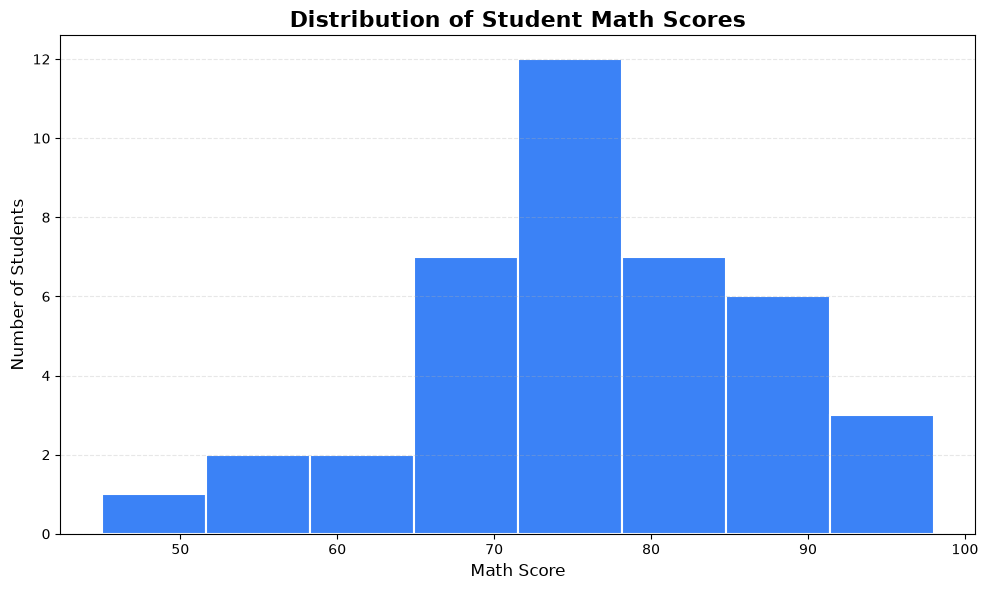

In [5]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["Math_Score"],
    bins=8,
    color="#3B82F6",
    edgecolor="white",
    linewidth=1.5
)

plt.title("Distribution of Student Math Scores",
          fontsize=16, fontweight="bold")
plt.xlabel("Math Score", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "math_score_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\HELLO\AppData\Local\Temp\ipykernel_19320\996883802.py:52: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


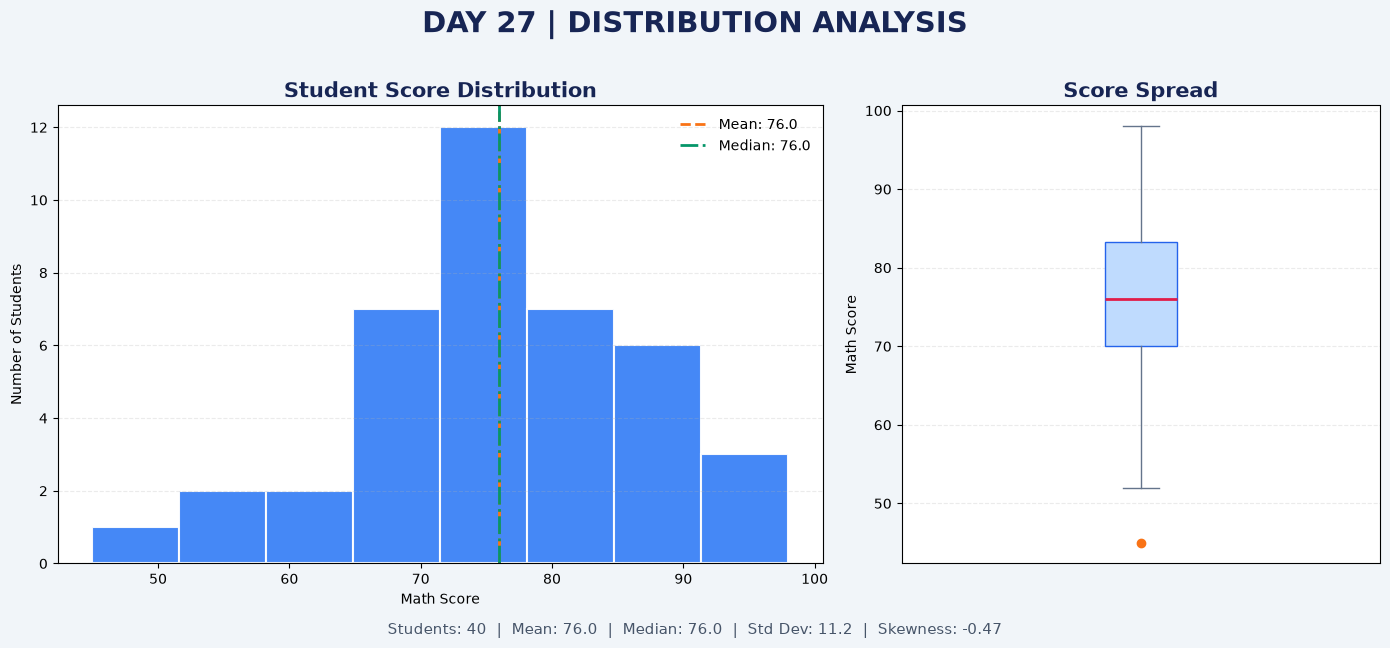

In [6]:
import numpy as np

scores = df["Math_Score"]

mean_score = scores.mean()
median_score = scores.median()
std_score = scores.std()
skewness = scores.skew()

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.6, 1]}
)

fig.patch.set_facecolor("#F1F5F9")

for ax in axes:
    ax.set_facecolor("white")

# Histogram
axes[0].hist(
    scores,
    bins=8,
    color="#3B82F6",
    edgecolor="white",
    linewidth=1.5,
    alpha=0.95
)

axes[0].axvline(
    mean_score, color="#F97316",
    linestyle="--", linewidth=2,
    label=f"Mean: {mean_score:.1f}"
)

axes[0].axvline(
    median_score, color="#059669",
    linestyle="-.", linewidth=2,
    label=f"Median: {median_score:.1f}"
)

axes[0].set_title(
    "Student Score Distribution",
    fontsize=15, fontweight="bold", color="#172554"
)
axes[0].set_xlabel("Math Score")
axes[0].set_ylabel("Number of Students")
axes[0].grid(axis="y", linestyle="--", alpha=0.25)
axes[0].legend(frameon=False)

# Boxplot for spread and possible outliers
axes[1].boxplot(
    scores,
    vert=True,
    patch_artist=True,
    boxprops={"facecolor": "#BFDBFE", "color": "#2563EB"},
    medianprops={"color": "#E11D48", "linewidth": 2},
    whiskerprops={"color": "#64748B"},
    capprops={"color": "#64748B"},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#F97316",
        "markeredgecolor": "#F97316"
    }
)

axes[1].set_title(
    "Score Spread",
    fontsize=15, fontweight="bold", color="#172554"
)
axes[1].set_ylabel("Math Score")
axes[1].set_xticks([])
axes[1].grid(axis="y", linestyle="--", alpha=0.25)

fig.suptitle(
    "DAY 27 | DISTRIBUTION ANALYSIS",
    fontsize=21, fontweight="bold",
    color="#172554", y=1.02
)

fig.text(
    0.5, -0.02,
    f"Students: {len(scores)}  |  Mean: {mean_score:.1f}"
    f"  |  Median: {median_score:.1f}"
    f"  |  Std Dev: {std_score:.1f}"
    f"  |  Skewness: {skewness:.2f}",
    ha="center", fontsize=11, color="#475569"
)

plt.tight_layout()
plt.savefig(
    "distribution_analysis_dashboard.png",
    dpi=300, bbox_inches="tight",
    facecolor=fig.get_facecolor()
)
plt.show()

In [7]:
scores = df["Math_Score"]

mean_score = scores.mean()
median_score = scores.median()
skewness = scores.skew()
score_range = scores.max() - scores.min()

q1 = scores.quantile(0.25)
q3 = scores.quantile(0.75)
iqr = q3 - q1

print("DISTRIBUTION ANALYSIS — OBSERVATIONS\n")

print(
    f"1. Central tendency: Mean = {mean_score:.2f}, "
    f"Median = {median_score:.2f}."
)

print(
    f"2. Spread: Scores range from {scores.min()} to "
    f"{scores.max()}, giving a range of {score_range} points."
)

if skewness > 0.5:
    shape = "positively skewed (right-skewed)"
elif skewness < -0.5:
    shape = "negatively skewed (left-skewed)"
else:
    shape = "approximately symmetric or only mildly skewed"

print(
    f"3. Shape: The distribution is {shape}; "
    f"skewness = {skewness:.3f}."
)

print(
    f"4. Middle 50%: Scores lie between Q1 = {q1:.2f} "
    f"and Q3 = {q3:.2f} (IQR = {iqr:.2f})."
)

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
potential_outliers = scores[
    (scores < lower_bound) | (scores > upper_bound)
]

print(
    f"5. Potential outliers using the 1.5×IQR rule: "
    f"{len(potential_outliers)}."
)

DISTRIBUTION ANALYSIS — OBSERVATIONS

1. Central tendency: Mean = 76.00, Median = 76.00.
2. Spread: Scores range from 45 to 98, giving a range of 53 points.
3. Shape: The distribution is approximately symmetric or only mildly skewed; skewness = -0.468.
4. Middle 50%: Scores lie between Q1 = 70.00 and Q3 = 83.25 (IQR = 13.25).
5. Potential outliers using the 1.5×IQR rule: 1.
